In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/cleaned_customer_data.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
# Calculate churn percentage for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn.round(2)

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


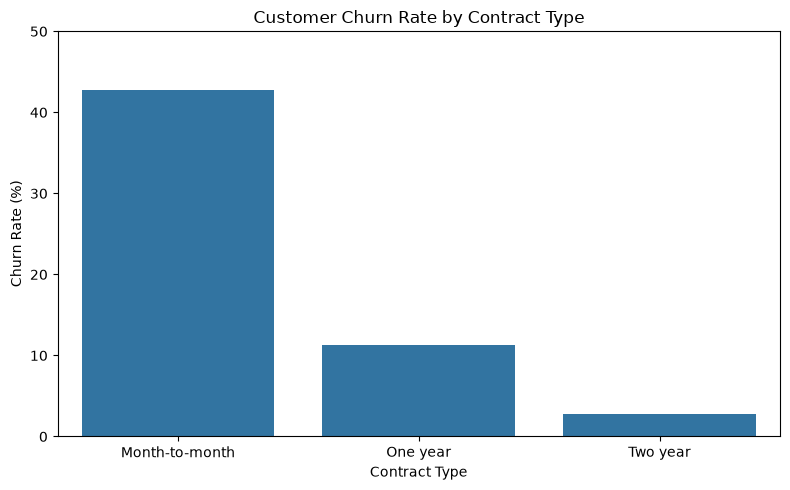

In [7]:
# Visualize churn rate by contract type

churn_rate_by_contract = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=churn_rate_by_contract.index,
    y=churn_rate_by_contract.values
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

plt.tight_layout()
plt.show()

In [8]:
# Group customers by tenure
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months",
            "25-48 months", "49-72 months"]
)

# Calculate churn rate for each tenure group
tenure_churn = (
    df.groupby("TenureGroup", observed=True)["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)

print("Churn Rate by Tenure Group:")
print(tenure_churn.round(2))

Churn Rate by Tenure Group:
TenureGroup
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64


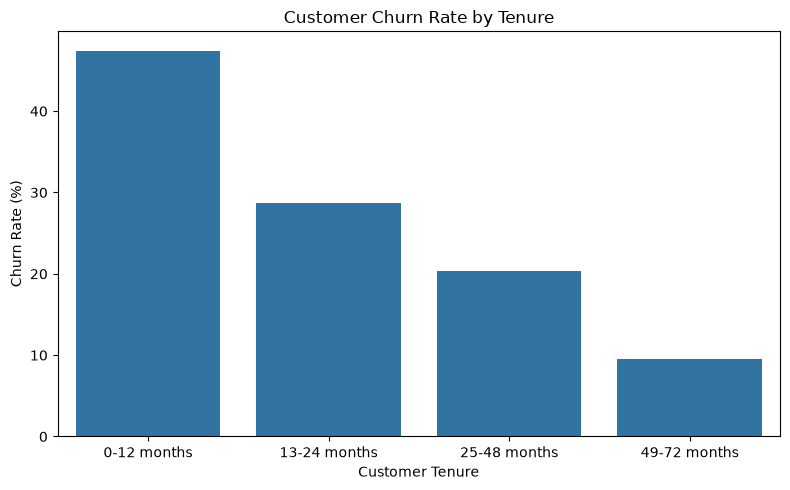

In [9]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values
)

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

In [10]:
# Compare monthly charges for customers who stayed vs churned

print(
    df.groupby("Churn")["MonthlyCharges"]
    .agg(["mean", "median"])
    .round(2)
)

        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65


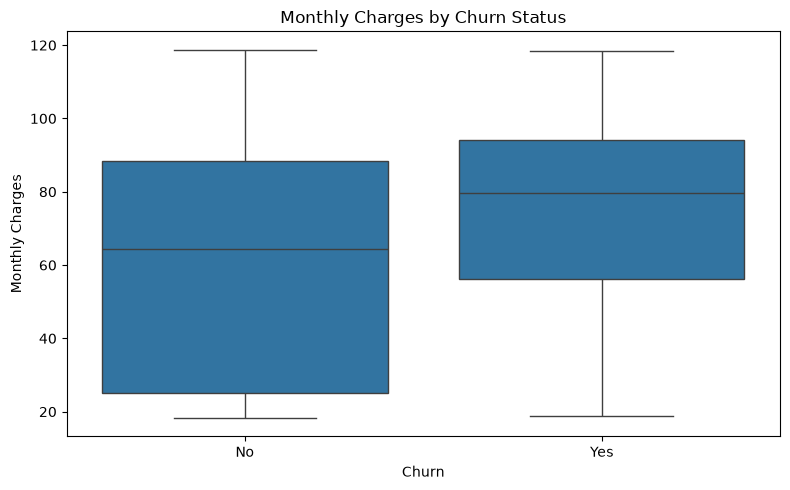

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

In [12]:
df.groupby("Churn")["MonthlyCharges"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
Churn,,,
No,5174,61.27,64.43
Yes,1869,74.44,79.65


In [13]:
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print(payment_churn.round(2))

PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


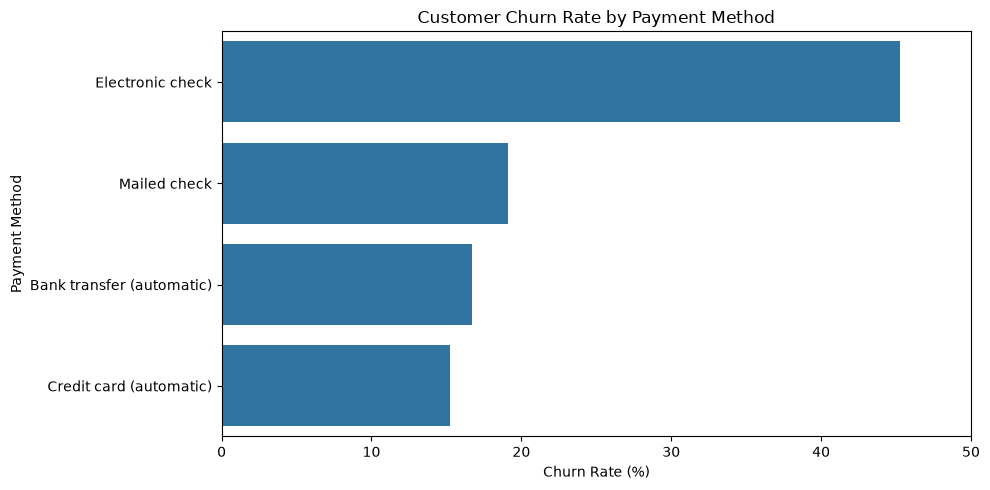

In [14]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_churn.values,
    y=payment_churn.index
)

plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Churn Rate (%)")
plt.ylabel("Payment Method")
plt.xlim(0, 50)

plt.tight_layout()
plt.show()

In [15]:
# Calculate churn rate by internet service
internet_churn = (
    df.groupby("InternetService")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Internet Service:")
print(internet_churn.round(2))

Churn Rate by Internet Service:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


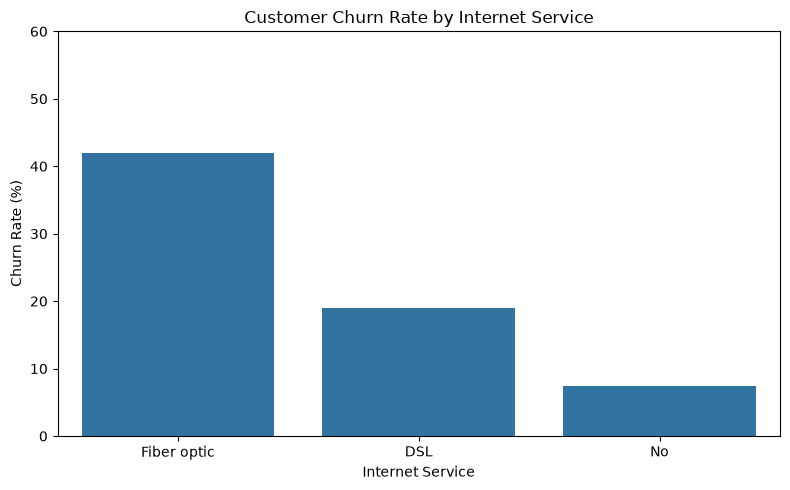

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 60)

plt.tight_layout()
plt.show()

In [17]:
# Calculate churn rate by tech support
support_churn = (
    df.groupby("TechSupport")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Tech Support:")
print(support_churn.round(2))

Churn Rate by Tech Support:
TechSupport
No                     41.64
Yes                    15.17
No internet service     7.40
Name: Churn, dtype: float64


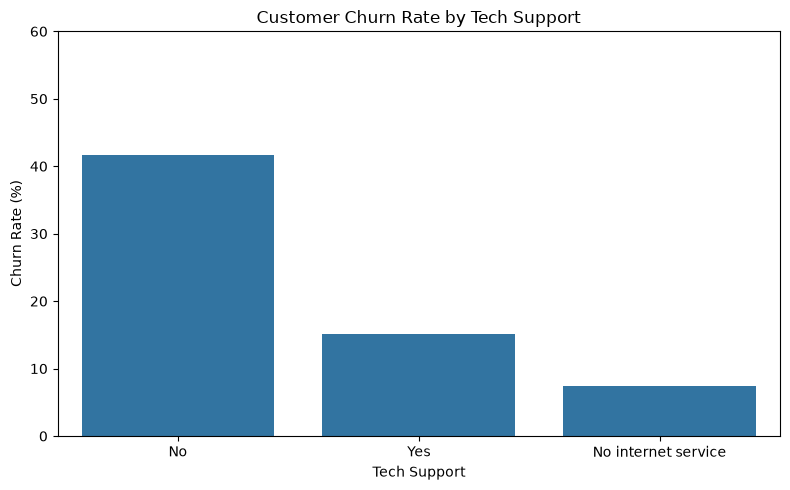

In [18]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=support_churn.index,
    y=support_churn.values
)

plt.title("Customer Churn Rate by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 60)

plt.tight_layout()
plt.show()

# Customer Churn — Initial EDA Findings

## Dataset overview
- Total customers: 7,043
- Churned customers: 1,869
- Overall churn rate: 26.54%
- Duplicate rows: 0
- Blank `TotalCharges` values found during inspection: 11

## Key observations
1. **Contract type:** Month-to-month customers have a churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.
2. **Tenure:** Churn is highest among customers with shorter tenure and decreases across the tenure groups.
3. **Monthly charges:** Churned customers have a higher median monthly charge than retained customers.
4. **Payment method:** Electronic-check customers have the highest churn rate at 45.29%.
5. **Internet service:** Fiber optic customers have the highest churn rate among the internet service groups.
6. **Tech support:** Customers without tech support have a substantially higher churn rate than customers with tech support.

## Business interpretation
The results suggest that early-tenure customers, month-to-month contract customers, electronic-check customers, and customers without tech support deserve further investigation.

These are descriptive associations, not evidence of causation. Additional analysis and model evaluation are needed before making retention recommendations.